## UNIT V: Exploratory Data Analysis (EDA)

### Data Processing, Feature Selection, Supervised Learning, Unsupervised Learning, Case Study

### Introduction to Exploratory Data Analysis

Exploratory Data Analysis (EDA) is a crucial step in any data science project. It involves summarizing the main characteristics of a dataset, often with visual methods. EDA helps to:

*   Understand the data's structure and content.
*   Identify patterns, anomalies, and relationships.
*   Formulate hypotheses for further analysis or modeling.
*   Detect outliers and missing values.

In this section, we will walk through a typical EDA workflow using a sample dataset and discuss its applicability to various domains like HR, Telecom, Healthcare, and Banking.

### 1. Setup: Importing Necessary Libraries

First, we import the essential Python libraries for data manipulation, visualization, and numerical operations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot styles
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
print("Libraries loaded successfully.")

Libraries loaded successfully.


### 2. Data Loading

For demonstration, we'll use the well-known `Titanic` dataset, which is a good example for illustrating various data types and potential issues. In a real-world scenario, you would load data specific to HR, Telecom, Healthcare, or Banking from CSV, Excel, SQL databases, or APIs.

*   **HR Data**: Employee records, performance reviews, salary, tenure, attrition.
*   **Telecom Data**: Customer call records, service usage, churn rates, contract details.
*   **Healthcare Data**: Patient demographics, medical history, diagnoses, treatment outcomes, insurance claims.
*   **Banking Data**: Customer transactions, loan applications, credit scores, default history, account balances.

In [2]:
# Load a sample dataset (Titanic dataset for demonstration)
df = sns.load_dataset('titanic')

print("Dataset loaded successfully. Displaying the first 5 rows:")
display(df.head())

Dataset loaded successfully. Displaying the first 5 rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 3. Initial Data Processing & Understanding

This step involves getting a general overview of the data, including its shape, data types, and basic statistics.

In [3]:
print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics for Numerical Columns:")
display(df.describe())

print("\nDescriptive Statistics for Categorical Columns:")
display(df.describe(include='object'))


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

Descriptive Statistics for Numerical Columns:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Descriptive Statistics for Categorical Columns:


,sex,embarked,who,embark_town,alive
count,891,889,891,889,891
unique,2,3,3,3,2
top,male,S,man,Southampton,no
freq,577,644,537,644,549


### 4. Handling Missing Values

Missing values are common in real-world datasets and can significantly impact analysis and model performance. It's crucial to identify them and decide on an appropriate strategy (e.g., imputation, removal).

*   **HR**: Missing performance ratings, missing tenure data.
*   **Telecom**: Missing service usage details.
*   **Healthcare**: Missing diagnostic results, patient demographics.
*   **Banking**: Missing credit scores, transaction details.

In [4]:
print("\nMissing Values before handling:")
display(df.isnull().sum())

# Strategy for 'age': Impute with median (common for skewed numerical data)
df['age'].fillna(df['age'].median(), inplace=True)

# Strategy for 'embarked': Impute with mode (common for categorical data)
df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)

# Strategy for 'deck': This column has a large number of missing values (almost 80%)
# and might not be directly useful without extensive feature engineering.
# For this demonstration, we'll drop it. In a real project, you'd assess its importance.
if 'deck' in df.columns:
    df.drop('deck', axis=1, inplace=True)

print("\nMissing Values after handling:")
display(df.isnull().sum())
print("Note: 'deck' column was dropped due to high missing values.")


Missing Values before handling:


,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0



Missing Values after handling:


/tmp/ipykernel_542/2769985835.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace=True)
/tmp/ipykernel_542/2769985835.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


Note: 'deck' column was dropped due to high missing values.


### 5. Feature Engineering (Basic) & Selection

Feature engineering involves creating new features from existing ones to improve model performance or provide deeper insights. Feature selection is about choosing the most relevant features.

Here, we'll create a simple feature 'FamilySize' and 'IsAlone' from 'sibsp' and 'parch'. We'll also consider which features are most relevant.

*   **HR**: Creating 'tenure_groups', 'salary_bins', 'promotion_rate'.
*   **Telecom**: 'avg_call_duration', 'data_usage_per_month', 'contract_renewal_flag'.
*   **Healthcare**: 'bmi', 'age_group', 'disease_severity_score'.
*   **Banking**: 'transaction_frequency', 'avg_transaction_amount', 'debt_to_income_ratio'.

In [5]:
# Create 'FamilySize' feature
df['FamilySize'] = df['sibsp'] + df['parch'] + 1  # +1 for the passenger themselves

# Create 'IsAlone' feature
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

print("\nNew features 'FamilySize' and 'IsAlone' created. Displaying head with new features:")
display(df.head())

# Example of potential feature selection based on domain knowledge or initial correlation
# For instance, 'pclass' might be a better indicator than a direct 'fare' for some models
# or 'sex' might be more important than 'name' for survival prediction.


New features 'FamilySize' and 'IsAlone' created. Displaying head with new features:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,FamilySize,IsAlone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,2,0
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,2,0
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,1,1
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,2,0
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,1,1


### 6. Exploratory Data Visualization

Visualizations are critical for understanding distributions, relationships, and identifying outliers or patterns. We'll use various plots to explore our dataset.

#### 6.1 Distribution of Numerical Features

Histograms and KDE plots help us understand the shape and spread of numerical data.

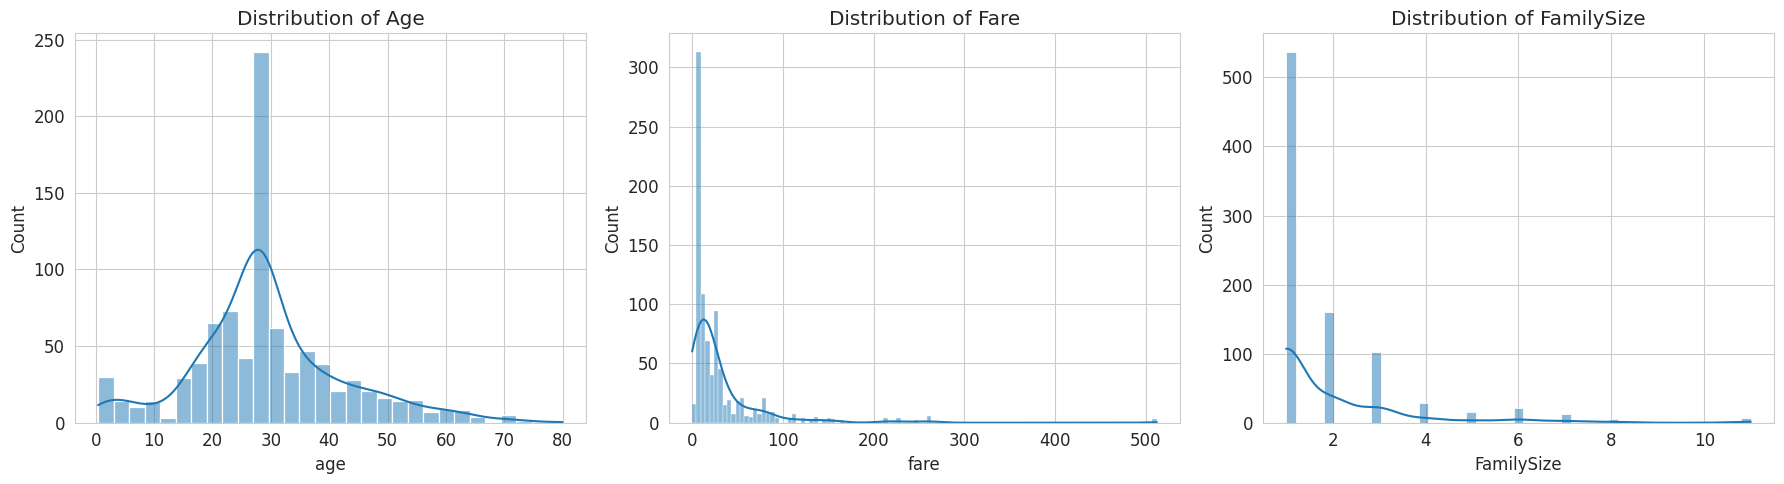

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['age'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of Age')

sns.histplot(df['fare'], kde=True, ax=axes[1])
axes[1].set_title('Distribution of Fare')

sns.histplot(df['FamilySize'], kde=True, ax=axes[2])
axes[2].set_title('Distribution of FamilySize')

plt.tight_layout()
plt.show()

#### 6.2 Distribution of Categorical Features

Count plots are excellent for visualizing the frequency of categories.

/tmp/ipykernel_542/85489664.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sex', data=df, ax=axes[0], palette='viridis')
/tmp/ipykernel_542/85489664.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='pclass', data=df, ax=axes[1], palette='magma')
/tmp/ipykernel_542/85489664.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='embarked', data=df, ax=axes[2], palette='cividis')
/tmp/ipykernel_542/85489664.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign t

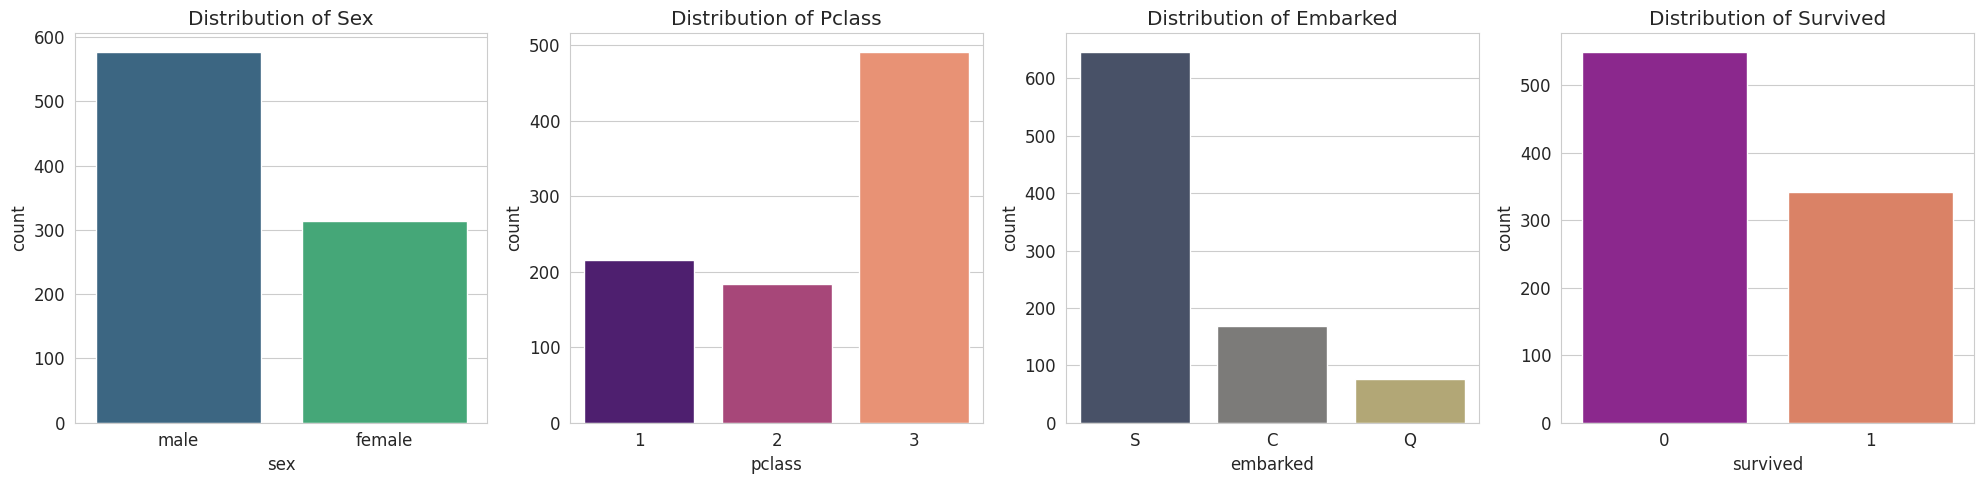

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

sns.countplot(x='sex', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of Sex')

sns.countplot(x='pclass', data=df, ax=axes[1], palette='magma')
axes[1].set_title('Distribution of Pclass')

sns.countplot(x='embarked', data=df, ax=axes[2], palette='cividis')
axes[2].set_title('Distribution of Embarked')

sns.countplot(x='survived', data=df, ax=axes[3], palette='plasma')
axes[3].set_title('Distribution of Survived')

plt.tight_layout()
plt.show()

#### 6.3 Relationships between Features (Numerical vs. Categorical)

Box plots and violin plots are useful for comparing numerical distributions across different categories.

/tmp/ipykernel_542/2418411858.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='pclass', y='age', data=df, ax=axes[0], palette='pastel')
/tmp/ipykernel_542/2418411858.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sex', y='age', data=df, ax=axes[1], palette='pastel')
/tmp/ipykernel_542/2418411858.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='survived', y='age', data=df, ax=axes[2], palette='pastel')


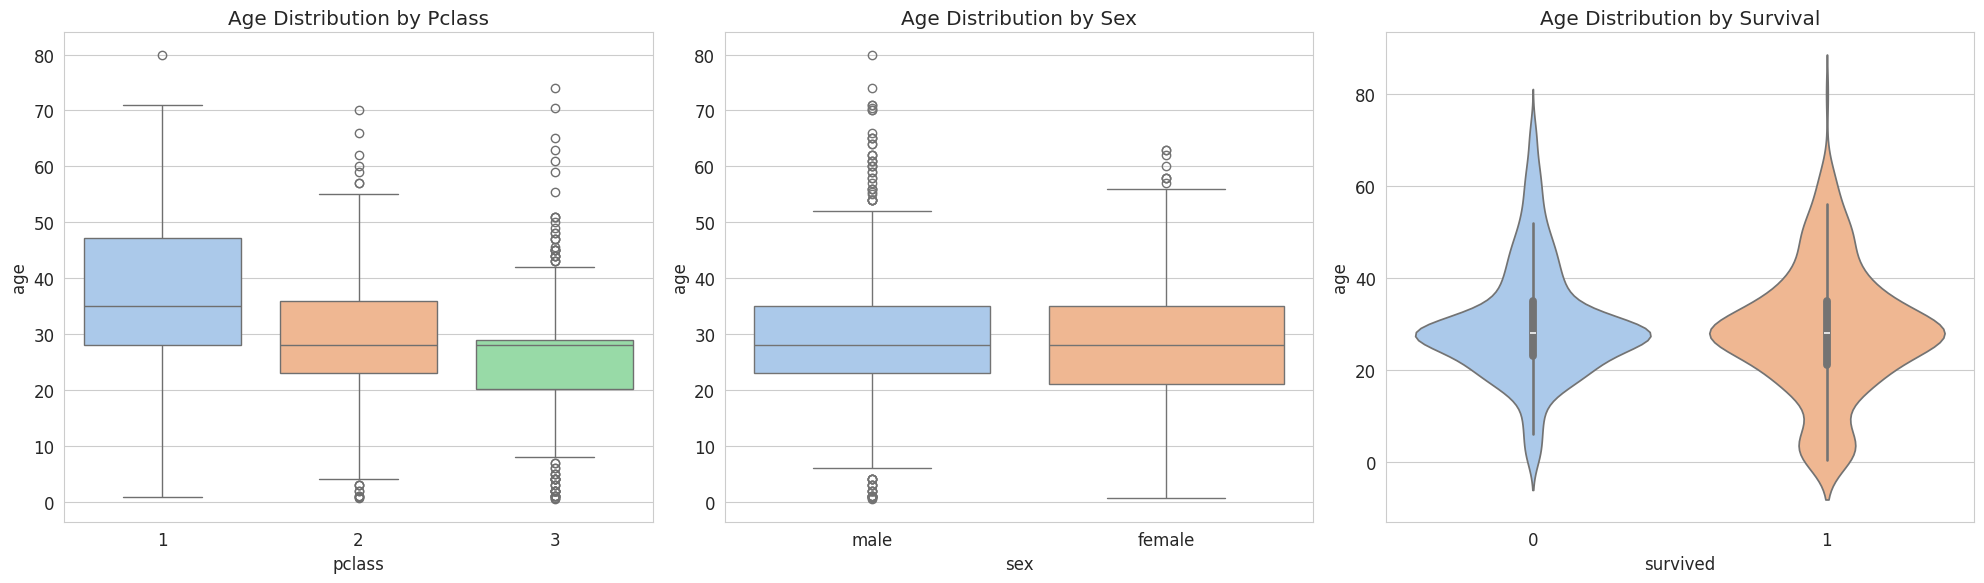

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.boxplot(x='pclass', y='age', data=df, ax=axes[0], palette='pastel')
axes[0].set_title('Age Distribution by Pclass')

sns.boxplot(x='sex', y='age', data=df, ax=axes[1], palette='pastel')
axes[1].set_title('Age Distribution by Sex')

sns.violinplot(x='survived', y='age', data=df, ax=axes[2], palette='pastel')
axes[2].set_title('Age Distribution by Survival')

plt.tight_layout()
plt.show()

#### 6.4 Relationships between Features (Categorical vs. Categorical)

Cross-tabulations and stacked bar charts help visualize relationships between two categorical variables.


Survival Rate by Sex:


survived,0,1
sex,,
female,0.257962,0.742038
male,0.811092,0.188908



Survival Rate by Pclass:


survived,0,1
pclass,,
1,0.370370,0.629630
2,0.527174,0.472826
3,0.757637,0.242363


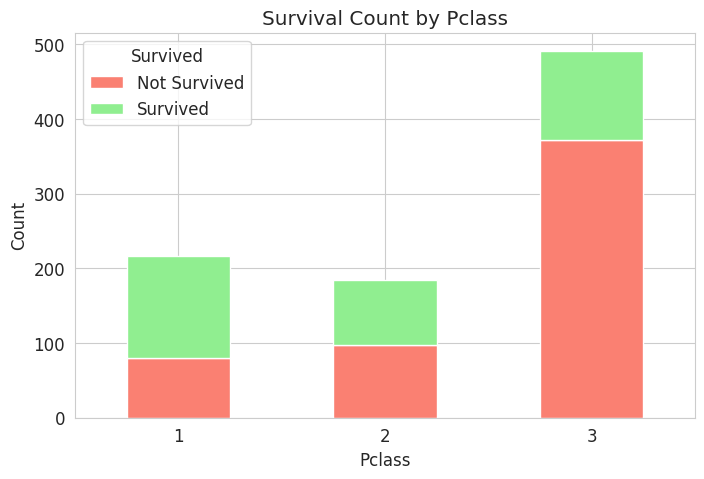

In [9]:
print("\nSurvival Rate by Sex:")
display(pd.crosstab(df['sex'], df['survived'], normalize='index'))

print("\nSurvival Rate by Pclass:")
display(pd.crosstab(df['pclass'], df['survived'], normalize='index'))

# Stacked bar plot for Pclass vs. Survival
pd.crosstab(df['pclass'], df['survived']).plot(kind='bar', stacked=True, figsize=(8, 5), color=['salmon', 'lightgreen'])
plt.title('Survival Count by Pclass')
plt.xlabel('Pclass')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(['Not Survived', 'Survived'], title='Survived')
plt.show()

#### 6.5 Correlation Matrix

Heatmaps of correlation matrices visualize the linear relationships between numerical features. This is crucial for feature selection and understanding multicollinearity.

*   **HR**: Correlation between salary and performance, tenure and attrition.
*   **Telecom**: Correlation between data usage and churn, call duration and plan type.
*   **Healthcare**: Correlation between age and disease incidence, medication dosage and recovery rate.
*   **Banking**: Correlation between credit score and loan default, account balance and transaction frequency.

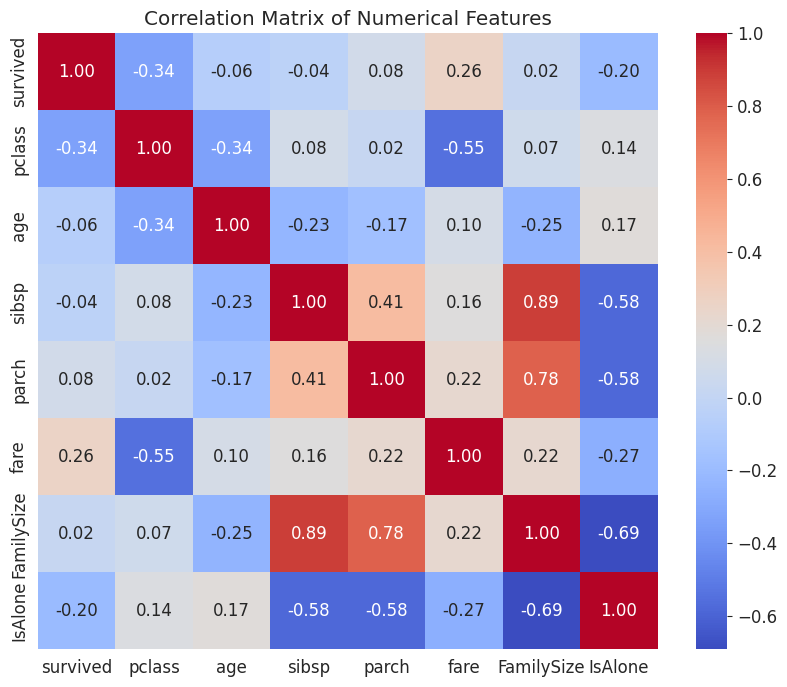

In [10]:
numerical_cols = df.select_dtypes(include=np.number).columns
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### 7. Case Studies on EDA

Let's consider how EDA principles apply to the specified domains without actual code, as no specific datasets were provided.

#### HR (Human Resources)

*   **Objective**: Understand employee attrition, performance, and satisfaction.
*   **EDA Steps & Insights**:
    *   **Data Cleaning**: Handle missing performance reviews, salary data.
    *   **Distributions**: Visualize salary distribution (e.g., histograms, box plots by department/role). Analyze age and tenure distributions.
    *   **Categorical Analysis**: Count plots for 'Department', 'Job Role', 'Education Level'. Crosstabulate 'Attrition' with 'Department', 'Job Satisfaction'.
    *   **Relationships**: Box plots of 'Salary' vs. 'Department', 'Performance Rating' vs. 'Attrition'. Scatter plots of 'Monthly Hours' vs. 'Overtime'.
    *   **Time Series (if applicable)**: Trend of attrition rates over time.
    *   **Feature Engineering**: Create 'YearsAtCompany', 'YearsInCurrentRole', 'AverageMonthlyHours'.
*   **Expected Findings**: Higher attrition in certain departments, lower satisfaction correlated with higher attrition, impact of promotion history on retention.

#### Telecom

*   **Objective**: Predict customer churn, understand service usage patterns.
*   **EDA Steps & Insights**:
    *   **Data Cleaning**: Impute missing call durations, data usage, contract end dates.
    *   **Distributions**: Histograms for 'Monthly Charges', 'Total Data Usage'. Count plots for 'Service Type', 'Contract Type'.
    *   **Categorical Analysis**: Crosstabulate 'Churn' with 'Contract Type', 'Internet Service', 'Payment Method'.
    *   **Relationships**: Box plots of 'Monthly Charges' vs. 'Churn'. Scatter plots of 'Total Data Usage' vs. 'Number of Calls'.
    *   **Feature Engineering**: 'AvgDailyDataUsage', 'ContractRemainingMonths', 'HasMultipleLines'.
*   **Expected Findings**: Customers with month-to-month contracts churn more, higher charges or specific service issues linked to churn.

#### Healthcare

*   **Objective**: Identify risk factors for diseases, understand treatment effectiveness, predict patient outcomes.
*   **EDA Steps & Insights**:
    *   **Data Cleaning**: Handle missing lab results, medical history entries, demographic information.
    *   **Distributions**: Histograms for 'Age', 'BMI', 'Blood Pressure'. Count plots for 'Diagnosis', 'Medication', 'Gender'.
    *   **Categorical Analysis**: Crosstabulate 'Disease Outcome' with 'Medication Type', 'Risk Factors' (e.g., smoking, diabetes).
    *   **Relationships**: Box plots of 'BMI' vs. 'Disease Outcome'. Scatter plots of 'Dosage' vs. 'Recovery Time'.
    *   **Feature Engineering**: 'AgeGroup', 'ComorbidityCount', 'TreatmentDuration'.
*   **Expected Findings**: Certain age groups or comorbidities have higher risk for specific diseases, effectiveness of different treatments.

#### Banking

*   **Objective**: Predict loan default, detect fraudulent transactions, understand customer segmentation.
*   **EDA Steps & Insights**:
    *   **Data Cleaning**: Impute missing credit scores, income details, transaction categories.
    *   **Distributions**: Histograms for 'Loan Amount', 'Credit Score', 'Account Balance'. Count plots for 'Loan Type', 'Account Type', 'Default Status'.
    *   **Categorical Analysis**: Crosstabulate 'Loan Default' with 'Credit Score Range', 'Income Level', 'Employment Status'.
    *   **Relationships**: Box plots of 'Credit Score' vs. 'Loan Default'. Scatter plots of 'Transaction Frequency' vs. 'Account Balance'.
    *   **Feature Engineering**: 'DebtToIncomeRatio', 'AverageTransactionValue', 'LoanToValueRatio'.
*   **Expected Findings**: Lower credit scores and high debt-to-income ratios are strong indicators of default, unusual transaction patterns might indicate fraud.


### Conclusion

Exploratory Data Analysis is a foundational practice in data science. It helps us not only to understand our data deeply but also to communicate initial findings effectively through visualizations and summaries. By thoroughly exploring the data, we can make informed decisions about data cleaning, feature engineering, and ultimately, select the most appropriate models for our predictive tasks, whether in HR, Telecom, Healthcare, or Banking.